<a href="https://colab.research.google.com/github/stringbot/pillarsofcreation/blob/main/pillars_composite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installing astropy

In [ ]:
!pip install astropy astroquery reproject

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.4/193.4 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 379.8/379.8 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.7/363.7 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 39.0 MB/s eta 0:00:00
  Created wheel for pims: filename=PIMS-0.7-py3-none-any.whl size=84590 sha256=c02ea8c12e43ea3e3025b39f1091f90f3324eb62586414d023e0541df40990c4
  Stored in directory: /root/.cache/pip/wheels/be/9c/72/7cb84823aaa980c2e44064caae0ba869239270fac14f7129aa

Defunct code used to download images, no longer necessary as the images were saved to the computer.


In [ ]:
from astroquery.mast import Observations

obs = Observations.query_criteria(proposal_id="2739", instrument_name="NIRCAM/IMAGE")
# urilist = ["mast:JWST/product/jw02739-o001_t001_nircam_clear-f090w_i2d.fits",
#           "mast:JWST/product/jw02739-o001_t001_nircam_clear-f187n_i2d.fits",
#            "mast:JWST/product/jw02739-o001_t001_nircam_clear-f200w_i2d.fits",
# "mast:JWST/product/jw02739-o001_t001_nircam_clear-f335m_i2d.fits",
# "mast:JWST/product/jw02739-o001_t001_nircam_f444w-f470n_i2d.fits",
# "mast:JWST/product/jw02739-o001_t001_nircam_clear-f444w_i2d.fits",]


# for uri in urilist:
#     Observations.download_file(uri)

# Note: downloaded and copied to Google Drive

rendering it, however we did not normalize the brightness so everything is extremely dark except for a few stars

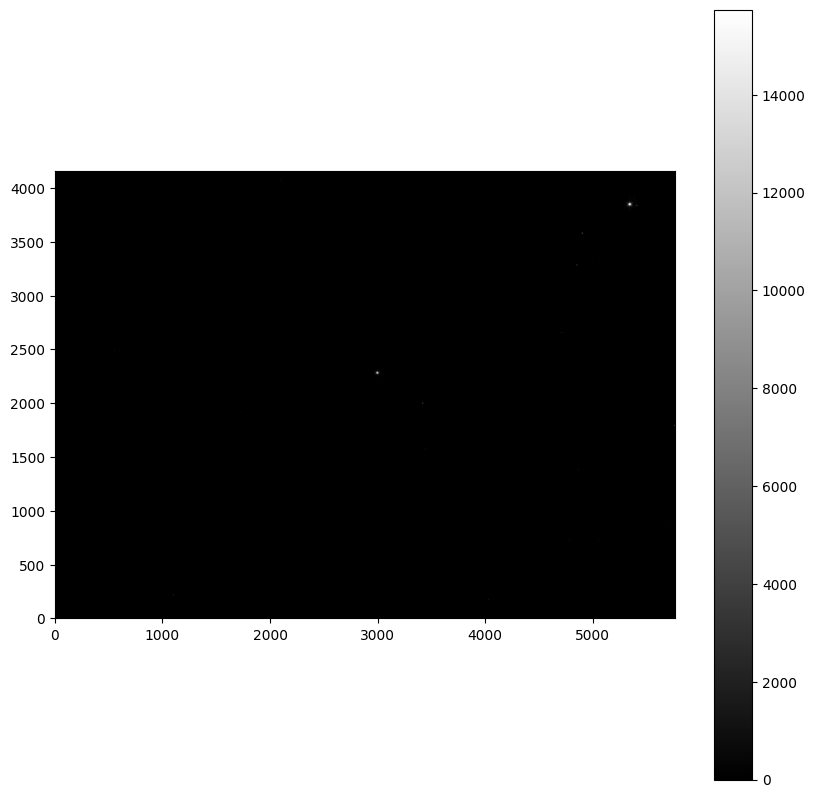

In [ ]:
from astropy.io import fits #Importing file type 
import matplotlib.pyplot as plt #and function

hdul = fits.open("/content/drive/Shareddrives/Pillars Share/cut_F090W.fits")
# ^defining variable as the path to a fits file
data = hdul[0].data

plt.figure(figsize=(10,10)) #rendering it with no modifications
plt.imshow(data, cmap="gray", origin="lower")
plt.colorbar()
plt.show()


adjusting brightness so the pillars are visible

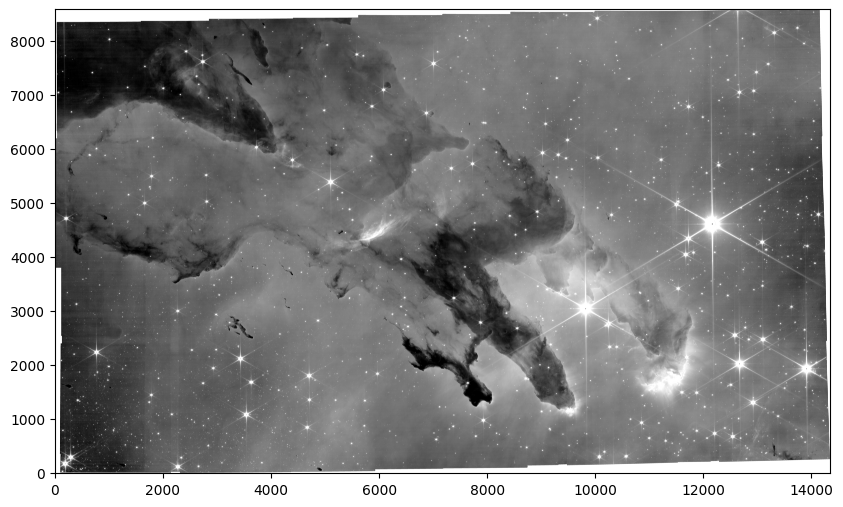

In [ ]:
from astropy.visualization import ImageNormalize, AsinhStretch, PercentileInterval

norm = ImageNormalize(data, interval=PercentileInterval(99.1), stretch=AsinhStretch()) #normalizes range of image brightness so as to make it visible

plt.figure(figsize=(10,10))
plt.imshow(data, cmap="gray", norm=norm, origin="lower")
plt.show()

defining various variables used to render the image in color

In [ ]:
from reproject import reproject_interp
from astropy.io import fits
# hdul = fits.open("/content/mastDownload/JWST/jw02739004001_02107_00004_nrcb2/jw02739004001_02107_00004_nrcb2_i2d.fits")

hdu_blue = fits.open("/content/drive/Shareddrives/Pillars Share/cut_F090W.fits")[0]
hdu_green = fits.open("/content/drive/Shareddrives/Pillars Share/cut_F200W.fits")[0]
hdu_red = fits.open("/content/drive/Shareddrives/Pillars Share/cut_F335M.fits")[0]

red_aligned, _ = reproject_interp(hdu_red, hdu_green.header)
blue_aligned, _ = reproject_interp(hdu_blue, hdu_green.header)
green_aligned = hdu_green.data

Set OBSGEO-B to   -29.108451 from OBSGEO-[XYZ].
Set OBSGEO-H to 1640894990.910 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -29.108451 from OBSGEO-[XYZ].
Set OBSGEO-H to 1640894990.910 from OBSGEO-[XYZ]'.
Set OBSGEO-B to   -29.098602 from OBSGEO-[XYZ].
Set OBSGEO-H to 1640754215.636 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -29.098602 from OBSGEO-[XYZ].
Set OBSGEO-H to 1640754215.636 from OBSGEO-[XYZ]'.
Set OBSGEO-B to   -29.108451 from OBSGEO-[XYZ].
Set OBSGEO-H to 1640894985.534 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -29.108451 from OBSGEO-[XYZ].
Set OBSGEO-H to 1640894985.534 from OBSGEO-[XYZ]'.


rendering image in color

/usr/local/lib/python3.12/dist-packages/astropy/visualization/lupton_rgb.py:645: RuntimeWarning: invalid value encountered in divide
  fInorm = np.where(Int <= 0, 0, np.true_divide(fI, Int))


<function matplotlib.pyplot.show(close=None, block=None)>

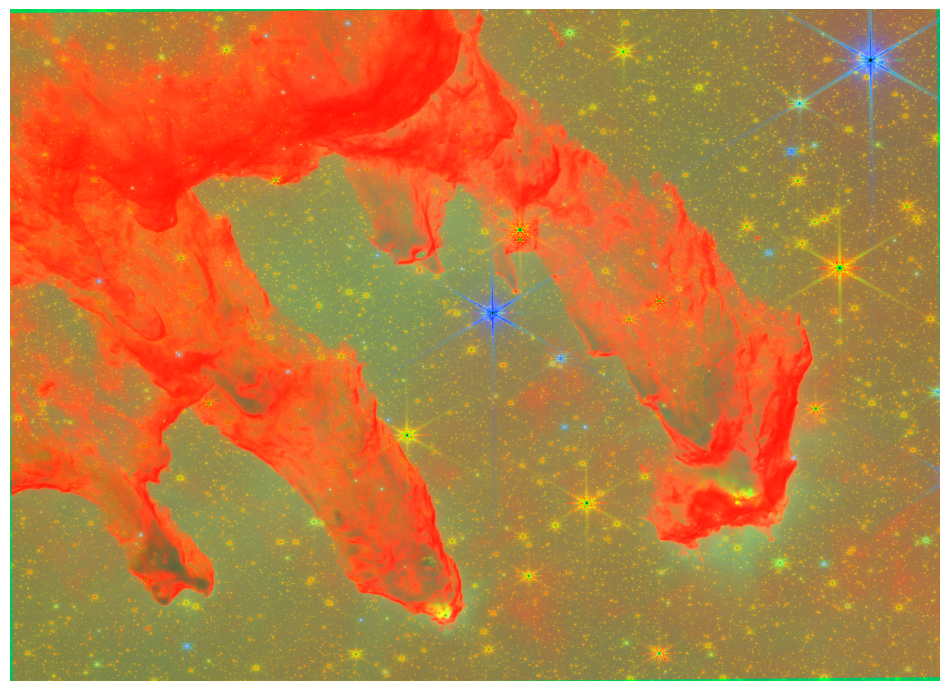

In [ ]:
from astropy.visualization import make_lupton_rgb as intt
import numpy as np

r = np.nan_to_num(red_aligned)
g = np.nan_to_num(green_aligned)
b = np.nan_to_num(blue_aligned)

rgb = intt(0.3*r, 0.3*g, 0.3*b, Q=10, stretch=0.5)

plt.figure(figsize=(12, 12))
plt.imshow(rgb, origin="lower")
plt.axis("off")
plt.show


For next time: stretch the brightness so the pillars are visible